In [2]:
import numpy as np

#v_t+1 = rho * v_t - l_r * Gradient
#w_t+1 = w_t + v_t+1
class MomentumOptimizer:
  def __init__(self, lr=0.01, momentum=0.9):
    self.lr = lr
    self.momentum = momentum
    self.v = {} #속도(Velocity)를 저장할 딕셔러니

  def update(self, params, grads):
    if not self.v:
      for key, val in params.items():
        self.v[key] = np.zeros_like(val)

    for key in params.keys():
      self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
      params[key] += self.v[key]

In [6]:
class NesterovOptimizer:
    def __init__(self, lr = 0.01, momentum = 0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = {}

    def update(self, params, grads):
        if not self.v:
            for key, val in params.items():
                self.v[key] = np.zeros_like(val)
        for key in params.keys():
            v_prev = self.v[key]
            self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
            step = -self.momentum * v_prev + (1 + self.momentum) * self.v[key]

            params[key] += step

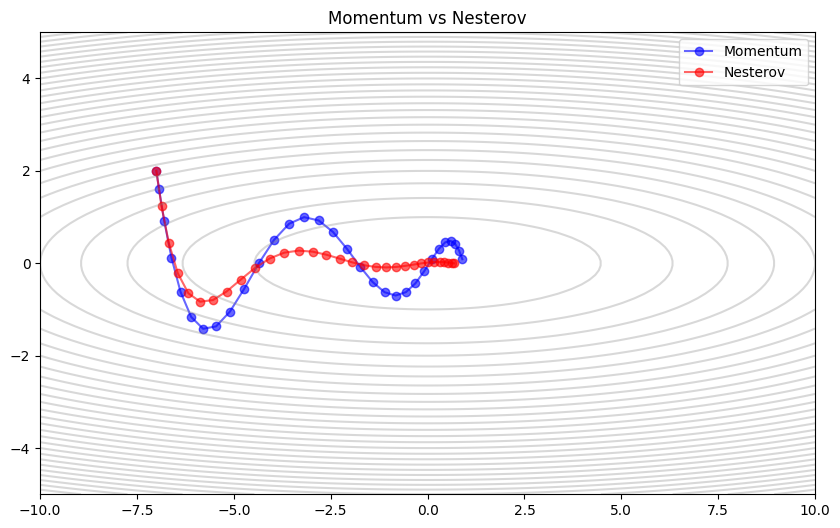

In [7]:
import matplotlib.pyplot as plt

# 테스트용 함수: f(x, y) = x^2 / 20 + y^2
# (한쪽으로 길쭉한 타원형이라 SGD가 지그재그로 움직이기 좋은 함수)
def f(x, y):
    return x**2 / 20.0 + y**2

def df(x, y):
    return {'x': x / 10.0, 'y': 2.0 * y}

# 초기 위치
init_pos = {'x': -7.0, 'y': 2.0}

def run_optimization(optimizer, init_pos, steps=30):
    params = init_pos.copy()
    path_x, path_y = [params['x']], [params['y']]

    for _ in range(steps):
        grads = df(params['x'], params['y'])
        optimizer.update(params, grads)
        path_x.append(params['x'])
        path_y.append(params['y'])

    return path_x, path_y

# 실행
mom_opt = MomentumOptimizer(lr=0.1, momentum=0.9)
nag_opt = NesterovOptimizer(lr=0.1, momentum=0.9)

mom_path = run_optimization(mom_opt, init_pos)
nag_path = run_optimization(nag_opt, init_pos)

# 시각화
plt.figure(figsize=(10, 6))
plt.plot(mom_path[0], mom_path[1], 'o-', label='Momentum', color='blue', alpha=0.6)
plt.plot(nag_path[0], nag_path[1], 'o-', label='Nesterov', color='red', alpha=0.6)
plt.contour(np.linspace(-10, 10, 100), np.linspace(-5, 5, 100),
            [[f(x, y) for x in np.linspace(-10, 10, 100)] for y in np.linspace(-5, 5, 100)],
            levels=30, colors='gray', alpha=0.3)
plt.title("Momentum vs Nesterov")
plt.legend()
plt.show()

In [13]:
class AdaGradOptimizer:
  def __init__(self, lr = 0.01):
    self.lr = lr
    self.h = {}
  def update(self, params, grads):
    if not self.h:
      for key, val in params.items():
        self.h[key] = np.zeros_like(val)

    for key in params.keys():
      self.h[key] += grads[key] * grads[key]
      params[key] -= self.lr * grads[key] / np.sqrt(self.h[key]+ 1e-7)

In [14]:
class RMSPropOptimizer:
  def __init__(self, lr = 0.01, decay_rate = 0.99):
    self. lr = lr
    self.decay_rate = decay_rate
    self. h = {}

  def update(self, params, grads):
    if not self.h:
      for key, val in params.items():
        self.h[key] = np.zeros_like(val)

    for key in params.keys():
      self.h[key] = self.decay_rate * self.h[key] + (1 - self.decay_rate) * (grads[key] * grads[key])
      params[key] -= self.lr * grads[key] / np.sqrt(self.h[key]+ 1e-7)

In [19]:
Ada = AdaGradOptimizer(lr=0.4)
RMS = RMSPropOptimizer(lr=0.4)

ada_path = run_optimization(Ada, init_pos)
rms_path = run_optimization(RMS, init_pos)

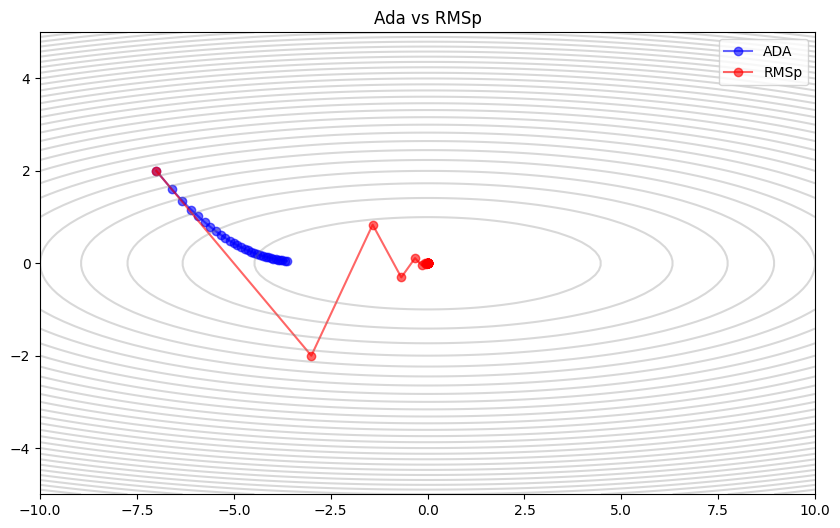

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(ada_path[0], ada_path[1], 'o-', label='ADA', color='blue', alpha=0.6)
plt.plot(rms_path[0], rms_path[1], 'o-', label='RMSp', color='red', alpha=0.6)
plt.contour(np.linspace(-10, 10, 100), np.linspace(-5, 5, 100),
            [[f(x, y) for x in np.linspace(-10, 10, 100)] for y in np.linspace(-5, 5, 100)],
            levels=30, colors='gray', alpha=0.3)
plt.title("Ada vs RMSp")
plt.legend()
plt.show()

In [25]:
class AdamOptimizer:
  def __init__(self, lr=0.3, beta1 = 0.9, beta2 = 0.999):
    self.lr = lr
    self.beta1 = beta1
    self.beta2 = beta2
    self.m = {}
    self.v = {}
    self.t = 0

  def update(self, params, grads):
    if not self.m:
      for key, val in params.items():
          self.m[key] = np.zeros_like(val)
          self.v[key] = np.zeros_like(val)

    self.t += 1
    lr_t = self.lr * np.sqrt(1.0 - self.beta2**self.t) / (1.0 - self.beta1**self.t)

    for key in params.keys():
      self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
      self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * (grads[key] ** 2)

      params[key] -= lr_t * self.m[key] / (np.sqrt(self.v[key]) + 1e-7)

In [26]:
Adam = AdamOptimizer(lr=0.3, beta1 = 0.9, beta2 = 0.999)

adam_path = run_optimization(Adam, init_pos)

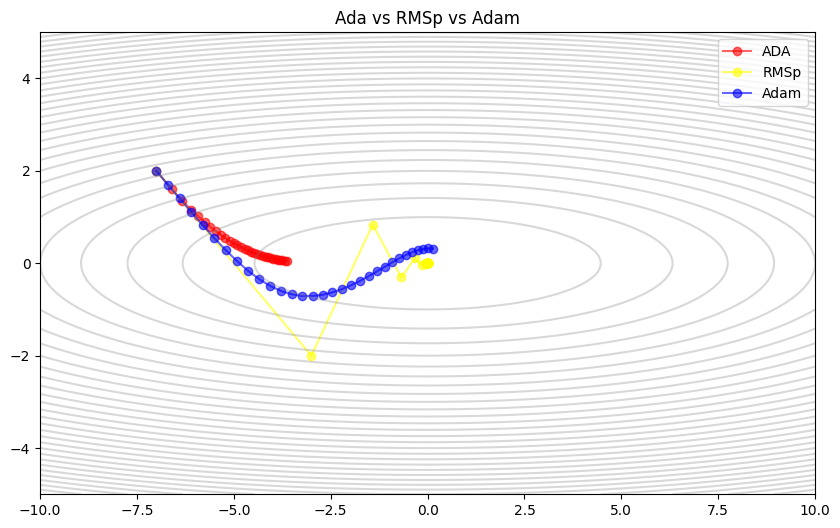

In [29]:
plt.figure(figsize=(10, 6))
plt.plot(ada_path[0], ada_path[1], 'o-', label='ADA', color='red', alpha=0.6)
plt.plot(rms_path[0], rms_path[1], 'o-', label='RMSp', color='yellow', alpha=0.6)
plt.plot(adam_path[0], adam_path[1], 'o-', label='Adam', color='blue', alpha=0.6)
plt.contour(np.linspace(-10, 10, 100), np.linspace(-5, 5, 100),
            [[f(x, y) for x in np.linspace(-10, 10, 100)] for y in np.linspace(-5, 5, 100)],
            levels=30, colors='gray', alpha=0.3)
plt.title("Ada vs RMSp vs Adam")
plt.legend()
plt.show()

In [32]:
class NadamOptimizer: #Nesterov + RMSprop
  def __init__(self, lr=0.3, beta1 = 0.9, beta2 = 0.999):
    self.lr = lr
    self.beta1 = beta1
    self.beta2 = beta2
    self.m = {}
    self.v = {}
    self.t = 0

  def update(self, params, grads):
    if not self.m:
      for key, val in params.items():
          self.m[key] = np.zeros_like(val)
          self.v[key] = np.zeros_like(val)

    self.t += 1

    for key in params.keys():
      self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
      self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * (grads[key] ** 2)

      m_hat = self.m[key] / (1 - self.beta1 ** self.t)
      v_hat = self.v[key] / (1 - self.beta2 ** self.t)

      term1 = self.beta1 * m_hat
      term2 = (1 - self.beta1) * grads[key] / (1-self.beta1**self.t)

      current_stpe = term1 + term2

      params[key] -= self.lr * current_stpe / (np.sqrt(v_hat) + 1e-8)

In [33]:
Nadam = NadamOptimizer(lr=0.3, beta1 = 0.9, beta2 = 0.999)

Nadam_path = run_optimization(Nadam, init_pos)

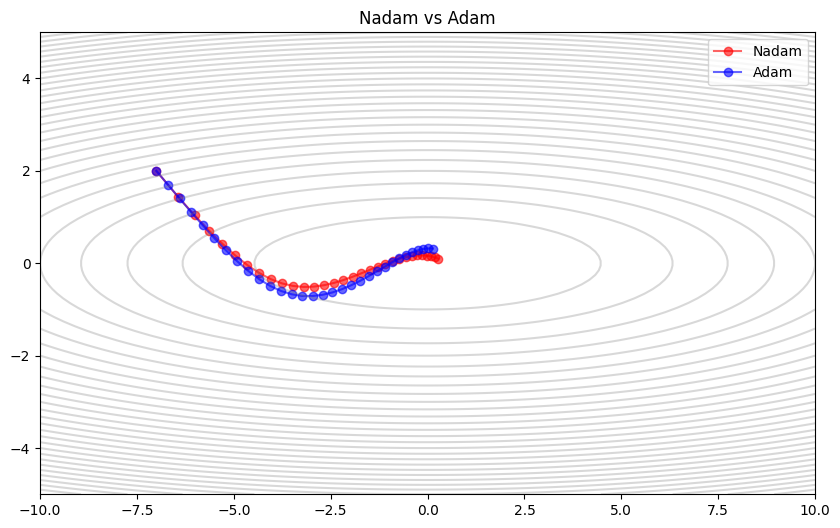

In [34]:
plt.figure(figsize=(10, 6))
plt.plot(Nadam_path[0], Nadam_path[1], 'o-', label='Nadam', color='red', alpha=0.6)
plt.plot(adam_path[0], adam_path[1], 'o-', label='Adam', color='blue', alpha=0.6)
plt.contour(np.linspace(-10, 10, 100), np.linspace(-5, 5, 100),
            [[f(x, y) for x in np.linspace(-10, 10, 100)] for y in np.linspace(-5, 5, 100)],
            levels=30, colors='gray', alpha=0.3)
plt.title("Nadam vs Adam")
plt.legend()
plt.show()

In [35]:
class SGDOptimizer:
    def __init__(self, lr=0.01):
        self.lr = lr

    def update(self, params, grads):
        for key in params.keys():
            params[key] -= self.lr * grads[key]